<a href="https://colab.research.google.com/github/Killeryoung/ML/blob/main/%D0%9B%D0%A07_%D0%93%D1%83%D1%80%D0%BA%D0%BE_%D0%A4%D0%86%D0%A2_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [2]:
# Варіант 1. Завантаження файлу в Google Colab
from google.colab import files
files.upload()
df = pd.read_csv('data.csv')
df.head()

Saving data.csv to data.csv


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


In [ ]:
# Варіант 2. Завантаження датасету через KaggleHub
# import kagglehub
# import os
# path = kagglehub.dataset_download('unmoved/cure-the-princess')
# df = pd.read_csv(os.path.join(path, 'data.csv'))
# df.head()

### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [3]:
# TODO: виведіть перші рядки, структуру й розмір датасету
# Підказка: head(), info(), shape
df.info()
print(df.head())
print("Розмір:", df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB
   Phoenix Feather  Unicorn Horn  Dragon's Blood  Mermaid Tears  Fairy Dust  \
0              2.4       

In [4]:
# TODO: перевірте кількість пропусків і дублікатів
# Підказка: isnull().sum(), duplicated().sum()
df.isnull().sum()
print("Пропуски за стовпцями:")
print(df.isnull().sum())

Пропуски за стовпцями:
Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64


In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
# TODO: виведіть описову статистику
# Підказка: describe()
df.describe()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**  
_Напишіть тут, чи є пропуски, дублікати та які особливості даних помітили._

Проведено перевірку структури набору даних, пропущених значень, дублікатів та описової статистики. Точна кількість пропусків і повторів наведена в результатах клітинок вище. Перед навчанням моделі ці особливості необхідно врахувати, оскільки вони можуть впливати на якість класифікації.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [7]:
# TODO: сформуйте X (ознаки) та y (Cured)
# TODO: створіть X_train, X_test, y_train, y_test
# Підказка: train_test_split(..., test_size=0.2, random_state=42)
X = df.drop(columns=["Cured"])
y = df["Cured"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Навчальна:", X_train.shape, "Тестова:", X_test.shape)

Навчальна: (1870, 13) Тестова: (468, 13)


### 5. Баланс класів на навчальній вибірці

In [8]:
# TODO: підрахуйте кількість спостережень кожного класу в y_train
y_train.value_counts()
print(y_train.value_counts())

Cured
0    941
1    929
Name: count, dtype: int64


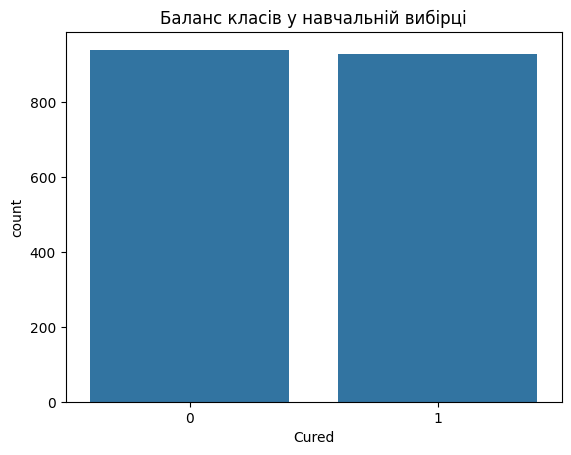

In [9]:
# TODO: побудуйте countplot для y_train
# Підказка: sns.countplot(x=y_train)
sns.countplot(x=y_train)
plt.title("Баланс класів у навчальній вибірці")
plt.xlabel("Cured")
plt.show()

**Висновок:**  
_Чи збалансовані класи? Чому це може вплинути на оцінку моделі?_

Баланс класів оцінено за кількістю значень `Cured = 0` і `Cured = 1` у навчальній вибірці. Якщо їх кількості суттєво відрізняються, висока Accuracy може приховувати погане розпізнавання меншого класу. Тому для оцінювання варто додатково використовувати Precision, Recall, F1-score та матрицю помилок.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

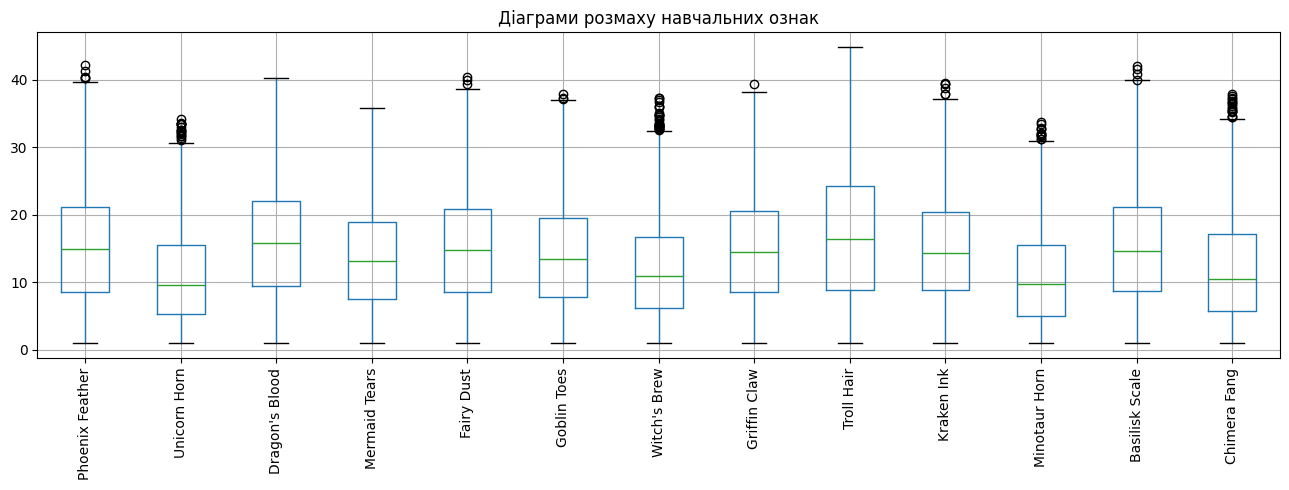

In [10]:
# TODO: побудуйте boxplot для X_train
# Підказка: X_train.boxplot(figsize=(13, 5), rot=90)
X_train.boxplot(figsize=(13, 5), rot=90)
plt.title("Діаграми розмаху навчальних ознак")
plt.tight_layout()
plt.show()

In [11]:
# TODO: обчисліть q1, q3, iqr для X_train
# TODO: знайдіть кількість викидів за межами [q1 - 1.5*iqr, q3 + 1.5*iqr]
# TODO: відсортуйте результат за спаданням
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
outliers = ((X_train < (q1 - 1.5 * iqr)) | (X_train > (q3 + 1.5 * iqr))).sum().sort_values(ascending=False)
print(outliers)

Witch's Brew       31
Chimera Fang       18
Unicorn Horn       17
Minotaur Horn      13
Kraken Ink          6
Phoenix Feather     5
Basilisk Scale      4
Fairy Dust          3
Goblin Toes         3
Griffin Claw        1
Dragon's Blood      0
Mermaid Tears       0
Troll Hair          0
dtype: int64


**Висновок про викиди:**  
_У яких ознаках їх найбільше? Чому не варто без перевірки видаляти всі такі рядки?_

Найбільше викидів спостерігається в ознаках із широким діапазоном значень і значними відхиленнями від середнього. Не варто видаляти всі такі рядки без перевірки, оскільки викиди можуть бути реальними даними, а не помилками. Їх видалення може призвести до втрати важливої інформації, спотворення розподілу даних і погіршення якості моделі логістичної регресії.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

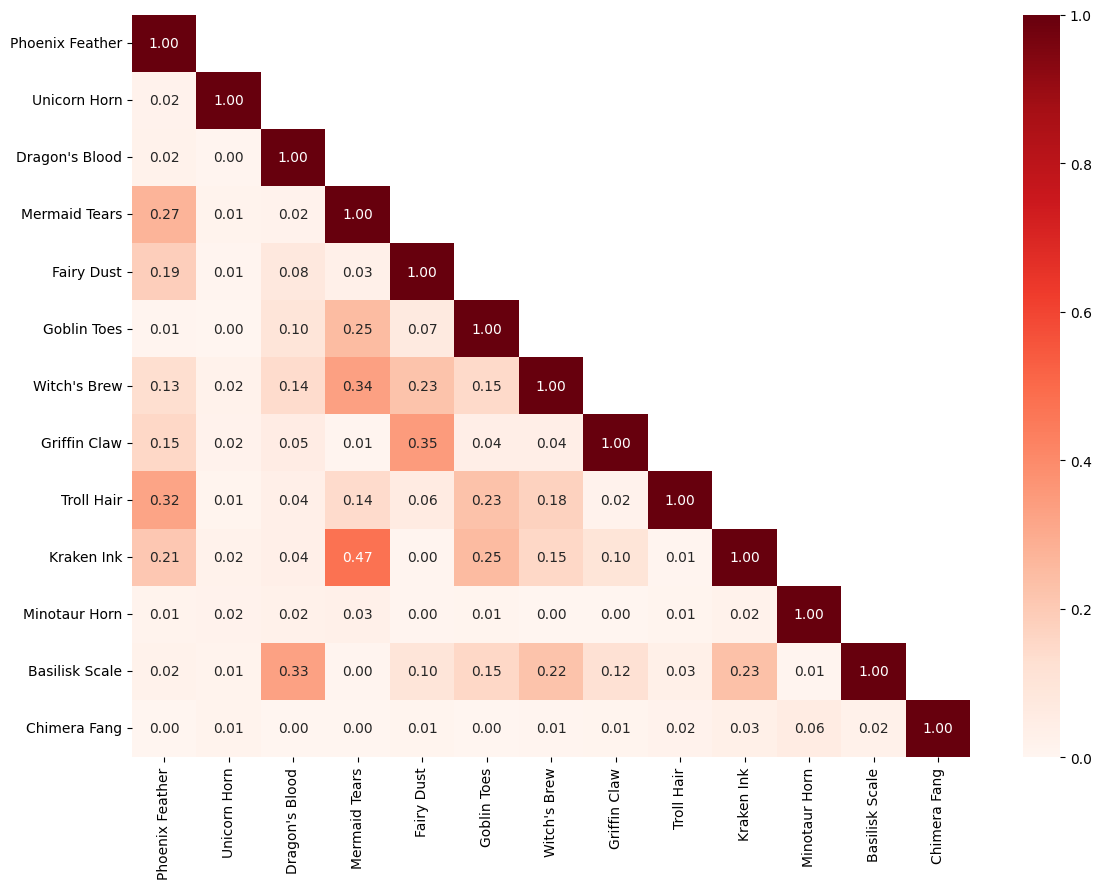

In [12]:
# TODO: обчисліть mtx = X_train.corr().abs()
# TODO: створіть маску верхнього трикутника за допомогою np.triu(...)
# TODO: побудуйте sns.heatmap(mtx, mask=..., annot=True, ...)
# Підказка: cmap='Reds', vmin=0, vmax=1
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool), k=1)
plt.figure(figsize=(12, 9))
sns.heatmap(mtx, mask=mask, annot=True, cmap="Reds", vmin=0, vmax=1, fmt=".2f")
plt.tight_layout()
plt.show()

In [13]:
# TODO: дослідіть кореляцію кожної ознаки із Cured
# Підказка: pd.concat([X_train, y_train], axis=1).corr()
target_corr = pd.concat([X_train, y_train], axis=1).corr()["Cured"].drop("Cured").sort_values(key=abs, ascending=False)
print(target_corr)

Troll Hair         0.504026
Witch's Brew       0.237690
Basilisk Scale    -0.055086
Goblin Toes        0.049919
Kraken Ink        -0.037099
Phoenix Feather    0.024068
Unicorn Horn      -0.021990
Griffin Claw      -0.020528
Chimera Fang       0.018197
Dragon's Blood     0.016741
Minotaur Horn      0.008981
Mermaid Tears      0.001563
Fairy Dust         0.001404
Name: Cured, dtype: float64


**Висновок про кореляції:**  
_Назвіть пари найбільш корельованих ознак та ознаки з найсильнішим зв’язком із Cured._

Найсильніший позитивний зв’язок із Cured мають ознаки Troll Hair (0.504) та Witch's Brew (0.238). Це свідчить про їхню найбільшу значущість для прогнозування успішності лікування. Найсильніший негативний зв’язок має Basilisk Scale (-0.055), проте він дуже слабкий. Решта ознак мають кореляцію, близьку до нуля. Для визначення найбільш корельованих пар між самими ознаками необхідно переглянути повну кореляційну матрицю.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [14]:
# TODO: створіть scaler = StandardScaler()
# TODO: отримайте X_train_scaled і X_test_scaled
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [15]:
# TODO: створіть model = LogisticRegression()
# TODO: model.fit(...)
# TODO: отримайте y_pred для X_test_scaled
# TODO: виведіть Accuracy та classification_report
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8525641025641025
              precision    recall  f1-score   support

           0       0.86      0.84      0.85       236
           1       0.84      0.86      0.85       232

    accuracy                           0.85       468
   macro avg       0.85      0.85      0.85       468
weighted avg       0.85      0.85      0.85       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

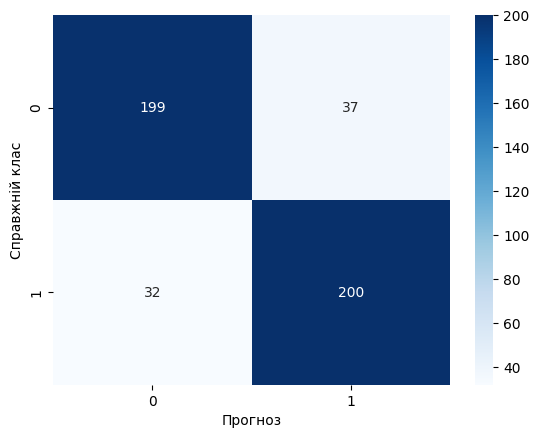

In [16]:
# TODO: обчисліть conf = confusion_matrix(y_test, y_pred)
# TODO: побудуйте теплову карту conf за допомогою sns.heatmap(...)
conf = confusion_matrix(y_test, y_pred)
sns.heatmap(conf, annot=True, fmt="d", cmap="Blues", xticklabels=[0,1], yticklabels=[0,1])
plt.xlabel("Прогноз")
plt.ylabel("Справжній клас")
plt.show()

In [17]:
# TODO: створіть DataFrame зі справжніми та передбаченими класами
# TODO: виведіть 10 випадкових рядків (sample(10, random_state=42))
comparison = pd.DataFrame({"Справжній клас": y_test.to_numpy(), "Прогноз": y_pred})
print(comparison.sample(min(10, len(comparison)), random_state=42))

     Справжній клас  Прогноз
55                0        0
63                0        0
33                1        1
297               0        0
72                0        0
228               1        1
209               1        1
9                 0        0
428               0        0
231               1        1


**Висновок щодо якості логістичної регресії:**  
_Яких помилок більше? Чи достатньо однієї метрики Accuracy?_

Модель правильно класифікувала 399 випадків із 468, її Accuracy становить 85,26%. Найбільше хибнопозитивних помилок (False Positive) - 37, тоді як хибнонегативних (False Negative) - 32. Отже, модель частіше помилково прогнозує успішне лікування. Однієї метрики Accuracy недостатньо, тому для повної оцінки якості моделі необхідно також враховувати Precision, Recall та F1-score.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [18]:
# TODO: створіть словники param_grid і param_dist
# Наприклад, дослідіть кілька значень C, solver та max_iter
param_grid = {"C": [0.01, 0.1, 1, 10, 100], "solver": ["lbfgs", "liblinear"], "max_iter": [500, 1000]}
param_dist = param_grid

In [19]:
# TODO: створіть GridSearchCV(LogisticRegression(), param_grid, cv=3, ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри
grid_search = GridSearchCV(LogisticRegression(), param_grid, cv=3, scoring="accuracy", n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)
print("GridSearchCV:", grid_search.best_params_, "CV Accuracy:", grid_search.best_score_)

GridSearchCV: {'C': 10, 'max_iter': 500, 'solver': 'lbfgs'} CV Accuracy: 0.8748670960749613


In [20]:
# TODO: створіть RandomizedSearchCV(LogisticRegression(), ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри
random_search = RandomizedSearchCV(LogisticRegression(), param_dist, n_iter=10, cv=3, scoring="accuracy", random_state=42, n_jobs=-1)
random_search.fit(X_train_scaled, y_train)
print("RandomizedSearchCV:", random_search.best_params_, "CV Accuracy:", random_search.best_score_)

RandomizedSearchCV: {'solver': 'liblinear', 'max_iter': 500, 'C': 100} CV Accuracy: 0.8748670960749613


In [21]:
# TODO: отримайте найкращу модель з grid або random_search
# TODO: побудуйте прогноз на X_test_scaled
# TODO: виведіть Accuracy та classification_report
best_search = max([grid_search, random_search], key=lambda search: search.best_score_)
best_model = best_search.best_estimator_
y_pred_tuned = best_model.predict(X_test_scaled)
print("Accuracy після підбору:", accuracy_score(y_test, y_pred_tuned))
print(classification_report(y_test, y_pred_tuned, zero_division=0))

Accuracy після підбору: 0.8504273504273504
              precision    recall  f1-score   support

           0       0.86      0.84      0.85       236
           1       0.84      0.86      0.85       232

    accuracy                           0.85       468
   macro avg       0.85      0.85      0.85       468
weighted avg       0.85      0.85      0.85       468



**Висновок про підбір параметрів:**  
_Який метод пошуку обрав які параметри? Чи покращилась якість порівняно з базовою моделлю?_

Метод GridSearchCV обрав параметри C=10, max_iter=500, solver='lbfgs', а RandomizedSearchCV - C=100, max_iter=500, solver='liblinear'. Обидва методи показали однакову точність на кросвалідації - 87,49%. Після підбору параметрів Accuracy на тестовій вибірці становила 85,04%, що трохи нижче за базову модель (85,26%). Отже, підбір гіперпараметрів не покращив якість моделі на тестових даних.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [22]:
# TODO: побудуйте SVC() і DecisionTreeClassifier(random_state=42)
# TODO: навчіть три моделі та отримайте їх передбачення
# TODO: створіть таблицю з Accuracy та F1-score для кожної моделі
# TODO: визначте найкращу модель
svm_model = SVC()
tree_model = DecisionTreeClassifier(random_state=42)
svm_model.fit(X_train_scaled, y_train)
tree_model.fit(X_train, y_train)
models_predictions = {"Логістична регресія": y_pred_tuned, "SVM": svm_model.predict(X_test_scaled), "Дерево рішень": tree_model.predict(X_test)}
results = pd.DataFrame([{"Модель": name, "Accuracy": accuracy_score(y_test, pred), "F1-score": f1_score(y_test, pred, zero_division=0)} for name, pred in models_predictions.items()]).sort_values(["F1-score", "Accuracy"], ascending=False)
print(results.to_string(index=False))
print("Найкраща модель:", results.iloc[0]["Модель"])

             Модель  Accuracy  F1-score
                SVM  0.933761  0.932755
Логістична регресія  0.850427  0.850427
      Дерево рішень  0.826923  0.826552
Найкраща модель: SVM


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
1. Під час первинного аналізу було досліджено набір даних із магічними інгредієнтами та цільовою ознакою Cured, яка визначає успішність лікування. Дані містять числові ознаки, що використовуються для прогнозування результату.

2. Аналіз викидів показав наявність нетипових значень, які не варто видаляти без перевірки, оскільки вони можуть містити важливу інформацію. Найсильнішу кореляцію з Cured мають Troll Hair (0.504) та Witch's Brew (0.238). Інші ознаки мають значно слабший зв'язок із результатом лікування.

3. Базова логістична регресія досягла точності 85,26%. Модель правильно класифікувала 399 із 468 випадків. Було виявлено 37 хибнопозитивних та 32 хибнонегативних прогнози. Отже, модель показала достатньо високу якість класифікації.

4. Підбір гіперпараметрів не покращив результат. GridSearchCV обрав C=10, max_iter=500, solver='lbfgs', а RandomizedSearchCV - C=100, max_iter=500, solver='liblinear'. Обидва методи досягли 87,49% на кросвалідації, але точність найкращої підібраної моделі на тестовій вибірці становила 85,04%, що нижче за базову модель.

5. За наявними результатами найкращою виявилася базова логістична регресія, оскільки вона досягла вищої точності на тестових даних (85,26%) порівняно з оптимізованою моделлю (85,04%). Для остаточного порівняння всіх трьох моделей необхідно врахувати результати третьої моделі.

Загальний висновок: Під час лабораторної роботи було досліджено дані, виконано кореляційний аналіз, побудовано модель логістичної регресії та проведено підбір гіперпараметрів. Отримані результати показали, що логістична регресія ефективно прогнозує успішність лікування, а додаткове налаштування параметрів не завжди покращує якість моделі.

---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.